In [6]:
#  Importing IO, OS and ZipFile for dataset handling
import io, os, zipfile
#  Importing requests library to handle api
import requests
# Importing pandas for DataFrame / Data Handling
import pandas as pd
# Importing matplotlib for charts
import matplotlib.pyplot as plt
# Importing drive to store the data
from google.colab import drive

In [12]:
drive.mount('/content/drive')
Data_dir = '/content/drive/MyDrive/dallas_aq_transfer'
os.makedirs(Data_dir, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
YEARS = range(2019, 2026)  # 2019 to 2025
COUNTIES = {113: "Dallas", 439: "Tarrant", 85: "Collin", 121: "Denton"}

In [14]:
EPA_URL = "https://aqs.epa.gov/aqsweb/airdata/daily_{code}_{year}.zip"
KEEP_COLS = ["State Code", "County Code", "Site Num", "Sample Duration",
             "Date Local", "Arithmetic Mean", "1st Max Value", "AQI"]

def load_epa(code):
    path = f"{Data_dir}/epa_{code}.csv"
    if os.path.exists(path):              # skip download if already saved
        return pd.read_csv(path, parse_dates=["Date Local"])
    frames = []
    for year in YEARS:
        print("Downloading", code, year)
        resp = requests.get(EPA_URL.format(code=code, year=year), timeout=300)
        resp.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(resp.content)) as zf:
            df = pd.read_csv(zf.open(zf.namelist()[0]), usecols=KEEP_COLS,
                             low_memory=False)
        df = df[(df["State Code"] == 48) & (df["County Code"].isin(COUNTIES))]
        frames.append(df)
    out = pd.concat(frames, ignore_index=True)
    out["Date Local"] = pd.to_datetime(out["Date Local"])
    out.to_csv(path, index=False)
    return out

ozone_raw = load_epa("44201")
pm25_raw = load_epa("88101")

print(ozone_raw["Sample Duration"].unique())
print(pm25_raw["Sample Duration"].unique())

['8-HR RUN AVG BEGIN HOUR']
['24 HOUR' '1 HOUR' '24-HR BLK AVG']


In [15]:
# Ozone: daily maximum 8 hour average, in parts per million
oz = ozone_raw[ozone_raw["Sample Duration"] == "8-HR RUN AVG BEGIN HOUR"]
ozone_daily = (oz.groupby(["County Code", "Date Local"])["1st Max Value"]
                 .mean().rename("ozone").reset_index())

# PM2.5: daily average, in micrograms per cubic meter
pm25_daily = (pm25_raw.groupby(["County Code", "Date Local"])["Arithmetic Mean"]
                .mean().rename("pm25").reset_index())

aq = ozone_daily.merge(pm25_daily, on=["County Code", "Date Local"], how="outer")
aq["county"] = aq["County Code"].map(COUNTIES)
aq = aq.rename(columns={"Date Local": "date"}).drop(columns="County Code")
print(aq.groupby("county").size())

county
Collin     2542
Dallas     2557
Denton     2557
Tarrant    2557
dtype: int64


In [17]:
POINTS = {"Dallas": (32.78, -96.80), "Tarrant": (32.75, -97.33),
          "Collin": (33.20, -96.62), "Denton": (33.21, -97.13)}
WEATHER_VARS = ("temperature_2m_max,temperature_2m_mean,wind_speed_10m_max,"
                "relative_humidity_2m_mean,shortwave_radiation_sum,precipitation_sum")

def load_weather(county):
    lat, lon = POINTS[county]
    params = {"latitude": lat, "longitude": lon,
              "start_date": "2019-01-01", "end_date": "2025-12-31",
              "daily": WEATHER_VARS, "timezone": "America/Chicago"}
    r = requests.get("https://archive-api.open-meteo.com/v1/archive",
                     params=params, timeout=120)
    r.raise_for_status()
    w = pd.DataFrame(r.json()["daily"])
    w["date"] = pd.to_datetime(w.pop("time"))
    w["county"] = county
    return w

weather = pd.concat([load_weather(c) for c in POINTS], ignore_index=True)
weather.to_csv(f"{Data_dir}/weather.csv", index=False)

In [19]:
data = weather.merge(aq, on=["county", "date"], how="left")
data = data.sort_values(["county", "date"]).reset_index(drop=True)
data.to_csv(f"{Data_dir}/merged.csv", index=False)

print(data.shape)
print(data.isna().sum())   # how many days are missing per column
data.head()

(10228, 10)
temperature_2m_max              0
temperature_2m_mean             0
wind_speed_10m_max              0
relative_humidity_2m_mean       0
shortwave_radiation_sum         0
precipitation_sum               0
date                            0
county                          0
ozone                          15
pm25                         3003
dtype: int64


,temperature_2m_max,temperature_2m_mean,wind_speed_10m_max,relative_humidity_2m_mean,shortwave_radiation_sum,precipitation_sum,date,county,ozone,pm25
0,5.7,3.5,24.5,75,5.68,0.0,2019-01-01,Collin,0.016,NaN
1,2.3,1.2,19.8,87,1.28,15.8,2019-01-02,Collin,0.011,NaN
2,4.9,2.9,18.3,92,2.04,17.1,2019-01-03,Collin,0.015,NaN
3,13.0,5.8,24.4,75,12.39,0.0,2019-01-04,Collin,0.031,NaN
4,16.8,8.8,14.4,75,12.64,0.0,2019-01-05,Collin,0.035,NaN


In [20]:
WEATHER_COLS = ["temperature_2m_max", "temperature_2m_mean", "wind_speed_10m_max",
                "relative_humidity_2m_mean", "shortwave_radiation_sum", "precipitation_sum"]

data["ozone"] = data["ozone"] * 1000   # ppm to ppb

def fill_gaps(group):
    group = group.copy()
    group[["ozone", "pm25"]] = group[["ozone", "pm25"]].interpolate(
        limit=1, limit_area="inside")
    return group

data = data.groupby("county", group_keys=False).apply(fill_gaps)
print(data.groupby("county")[["ozone", "pm25"]].apply(lambda g: g.isna().sum()))

         ozone  pm25
county              
Collin       9  2557
Dallas       0     9
Denton       0   267
Tarrant      0    72


/tmp/ipykernel_1280/2986514786.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data = data.groupby("county", group_keys=False).apply(fill_gaps)


In [21]:
BASE_FEATURES = ["today", "minus_1", "minus_2", "minus_6", "roll_7", "month", "dow"]

def make_features(df, pollutant, horizon):
    parts = []
    for county, g in df.groupby("county"):
        g = g.sort_values("date").copy()
        g["today"] = g[pollutant]
        for k in [1, 2, 6]:
            g[f"minus_{k}"] = g[pollutant].shift(k)
        g["roll_7"] = g[pollutant].rolling(7).mean()
        g["month"] = g["date"].dt.month
        g["dow"] = g["date"].dt.dayofweek
        g["target"] = g[pollutant].shift(-horizon)
        g["target_date"] = g["date"] + pd.Timedelta(days=horizon)
        parts.append(g)
    out = pd.concat(parts)
    return out.dropna(subset=BASE_FEATURES + WEATHER_COLS + ["target"])

check = make_features(data, "ozone", 1)
check[["county", "date", "today", "minus_1", "target"]].head(10)

,county,date,today,minus_1,target
6,Collin,2019-01-07,35.0,41.0,38.0
7,Collin,2019-01-08,38.0,35.0,38.0
8,Collin,2019-01-09,38.0,38.0,27.0
9,Collin,2019-01-10,27.0,38.0,26.0
10,Collin,2019-01-11,26.0,27.0,23.0
11,Collin,2019-01-12,23.0,26.0,25.0
12,Collin,2019-01-13,25.0,23.0,23.0
13,Collin,2019-01-14,23.0,25.0,13.0
14,Collin,2019-01-15,13.0,23.0,23.0
15,Collin,2019-01-16,23.0,13.0,19.0


In [22]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

def score(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

def new_models():
    return {
        "Linear Regression": LinearRegression(),
        "XGBoost": XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                                subsample=0.8, random_state=42),
    }

HORIZONS = [1, 7, 14]
COUNTY_ORDER = ["Dallas", "Tarrant", "Collin", "Denton"]

In [24]:
rows = []
for pollutant in ["ozone", "pm25"]:
    for h in HORIZONS:
        feat = make_features(data, pollutant, h)
        train = feat[(feat["county"] == "Dallas") & (feat["target_date"].dt.year <= 2024)]
        test = feat[feat["date"].dt.year == 2025]

        for county, t in test.groupby("county"):
            mae, rmse = score(t["target"], t["today"])
            rows.append(dict(pollutant=pollutant, horizon=h, features="none",
                             model="Persistence", county=county, mae=mae, rmse=rmse))

        for feat_name, cols in [("no weather", BASE_FEATURES),
                                ("with weather", BASE_FEATURES + WEATHER_COLS)]:
            for name, model in new_models().items():
                model.fit(train[cols], train["target"])
                for county, t in test.groupby("county"):
                    mae, rmse = score(t["target"], model.predict(t[cols]))
                    rows.append(dict(pollutant=pollutant, horizon=h, features=feat_name,
                                     model=name, county=county, mae=mae, rmse=rmse))

results = pd.DataFrame(rows)
results.to_csv(f"{Data_dir}/results.csv", index=False)
print(len(results), "result rows")

105 result rows


In [25]:
table = results.pivot_table(index=["pollutant", "horizon", "model", "features"],
                            columns="county", values="rmse")[COUNTY_ORDER]
for c in ["Tarrant", "Collin", "Denton"]:
    table[f"gap {c} %"] = (table[c] - table["Dallas"]) / table["Dallas"] * 100
table["avg gap %"] = table[[f"gap {c} %" for c in ["Tarrant", "Collin", "Denton"]]].mean(axis=1)
table.round(2)

county                                            Dallas  Tarrant  Collin  \
pollutant horizon model             features                                
ozone     1       Linear Regression no weather      8.52     8.70    9.85   
                                    with weather    8.57     8.64    9.60   
                  Persistence       none            9.22     9.35   10.88   
                  XGBoost           no weather      8.75     8.85   10.22   
                                    with weather    8.81     8.74    9.66   
          7       Linear Regression no weather     11.84    11.89   12.62   
                                    with weather   11.89    11.93   12.59   
                  Persistence       none           14.31    14.82   15.35   
                  XGBoost           no weather     11.67    11.81   12.20   
                                    with weather   11.97    12.29   12.12   
          14      Linear Regression no weather     12.45    12.49   13.44   
                                    with weather   12.38    12.29   13.06   
                  Persistence       none           15.09    15.19   15.84   
                  XGBoost           no weather     12.07    12.25   12.93   
                                    with weather   12.66    12.68   13.10   
pm25      1       Linear Regression no weather      4.27     4.32     NaN   
                                    with weather    4.18     4.24     NaN   
                  Persistence       none            4.96     5.05     NaN   
                  XGBoost           no weather      4.28     4.37     NaN   
                                    with weather    4.14     4.26     NaN   
          7       Linear Regression no weather      4.87     4.63     NaN   
                                    with weather    4.81     4.65     NaN   
                  Persistence       none            6.66     6.46     NaN   
                  XGBoost           no weather      5.07     4.95     NaN   
                                    with weather    5.13     5.01     NaN   
          14      Linear Regression no weather      4.87     4.60     NaN   
                                    with weather    4.75     4.57     NaN   
                  Persistence       none            6.84     6.70     NaN   
                  XGBoost           no weather      4.94     4.93     NaN   
                                    with weather    5.17     4.98     NaN   

county                                            Denton  gap Tarrant %  \
pollutant horizon model             features                              
ozone     1       Linear Regression no weather      9.47           2.05   
                                    with weather    9.12           0.83   
                  Persistence       none           10.62           1.39   
                  XGBoost           no weather      9.88           1.13   
                                    with weather    9.11          -0.86   
          7       Linear Regression no weather     11.90           0.44   
                                    with weather   11.87           0.33   
                  Persistence       none           14.42           3.54   
                  XGBoost           no weather     12.10           1.21   
                                    with weather   11.80           2.63   
          14      Linear Regression no weather     12.50           0.35   
                                    with weather   12.09          -0.67   
                  Persistence       none           15.19           0.64   
                  XGBoost           no weather     12.07           1.52   
                                    with weather   12.18           0.19   
pm25      1       Linear Regression no weather      4.84           1.34   
                                    with weather    4.77           1.39   
                  Persistence       none            5.70           1.98   
                  XGBoost          

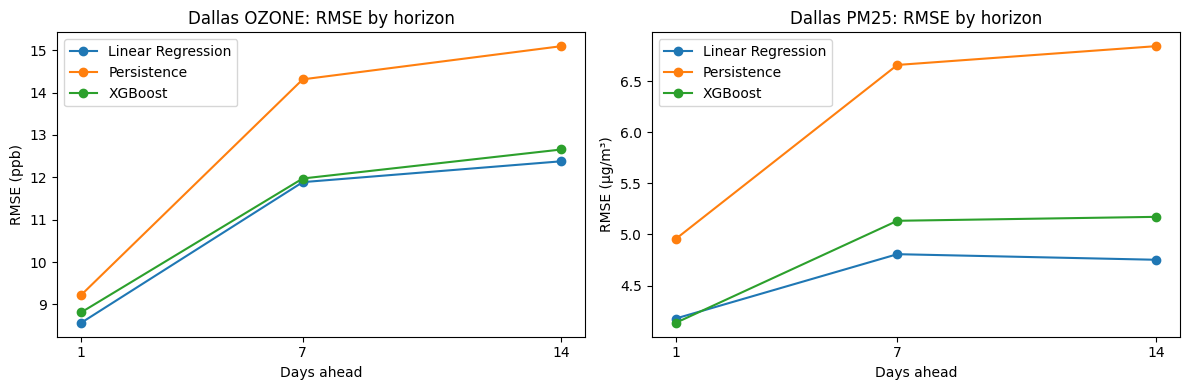

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pollutant, unit in zip(axes, ["ozone", "pm25"], ["ppb", "µg/m³"]):
    d = results[(results["pollutant"] == pollutant) & (results["county"] == "Dallas")]
    d = d[(d["features"] != "no weather")]          # persistence plus weather models
    for model, g in d.groupby("model"):
        g = g.sort_values("horizon")
        ax.plot(g["horizon"], g["rmse"], marker="o", label=model)
    ax.set_title(f"Dallas {pollutant.upper()}: RMSE by horizon")
    ax.set_xlabel("Days ahead"); ax.set_ylabel(f"RMSE ({unit})")
    ax.set_xticks(HORIZONS); ax.legend()
plt.tight_layout(); plt.savefig(f"{Data_dir}/chart_horizon.png", dpi=150); plt.show()

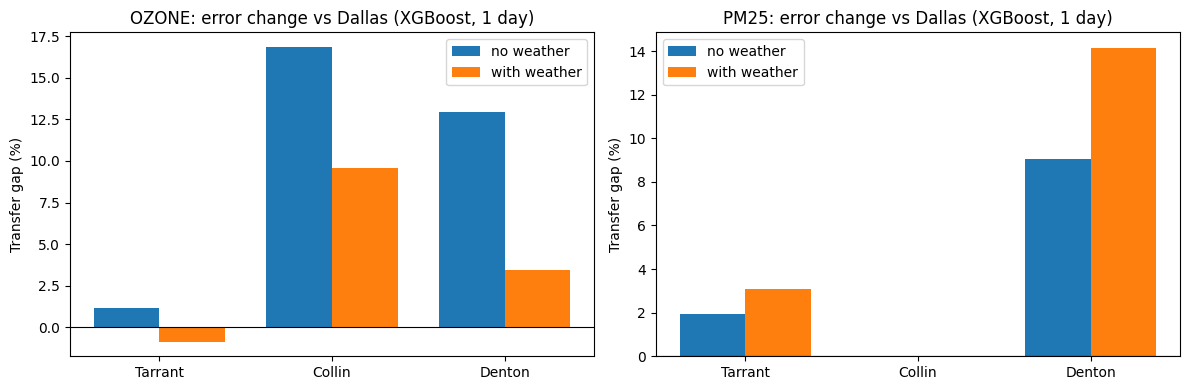

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
others = ["Tarrant", "Collin", "Denton"]
x = np.arange(len(others)); width = 0.38
for ax, pollutant in zip(axes, ["ozone", "pm25"]):
    for i, feat_name in enumerate(["no weather", "with weather"]):
        gaps = [table.loc[(pollutant, 1, "XGBoost", feat_name), f"gap {c} %"] for c in others]
        ax.bar(x + (i - 0.5) * width, gaps, width, label=feat_name)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x); ax.set_xticklabels(others)
    ax.set_title(f"{pollutant.upper()}: error change vs Dallas (XGBoost, 1 day)")
    ax.set_ylabel("Transfer gap (%)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{Data_dir}/chart_transfer.png", dpi=150); plt.show()

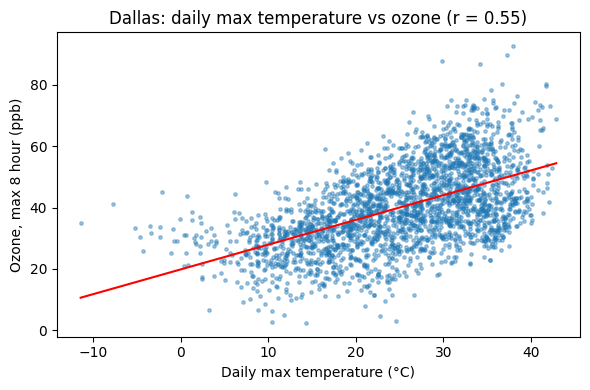

Ozone rises about 0.81 ppb per 1 °C


In [30]:
d = data[(data["county"] == "Dallas")].dropna(subset=["ozone", "temperature_2m_max"])
slope, intercept = np.polyfit(d["temperature_2m_max"], d["ozone"], 1)
corr = d["temperature_2m_max"].corr(d["ozone"])

plt.figure(figsize=(6, 4))
plt.scatter(d["temperature_2m_max"], d["ozone"], s=6, alpha=0.4)
xs = np.linspace(d["temperature_2m_max"].min(), d["temperature_2m_max"].max(), 50)
plt.plot(xs, slope * xs + intercept, color="red")
plt.title(f"Dallas: daily max temperature vs ozone (r = {corr:.2f})")
plt.xlabel("Daily max temperature (°C)"); plt.ylabel("Ozone, max 8 hour (ppb)")
plt.tight_layout(); plt.savefig(f"{Data_dir}/chart_heat_ozone.png", dpi=150); plt.show()
print(f"Ozone rises about {slope:.2f} ppb per 1 °C")